# ✈️ Proyecto Final: Predicción de Retrasos en Vuelos Comerciales de EE.UU.

## Especialización en Analítica y Ciencia de Datos — Machine Learning

**Universidad EIA**
**Autor:** Sebastián Olaya
**Dataset:** 2021–2026 US Flights (Bureau of Transportation Statistics · BTS / U.S. DOT), publicado en Kaggle
**Periodo de Estudio:** Junio de 2025 a Mayo de 2026 (12 meses calendario completos)

---

## 🧭 Ruta Metodológica Oficial de los 6 Pasos

1. **¿ML?** — Planteamiento del problema real, justificación de ML y formulación de una regla manual.
2. **Datos** — Fuente oficial, licencia, granularidad, cobertura mensual y definición del target.
3. **Limpieza** — Manejo de cancelaciones, desvíos y valores atípicos; tabla comparativa *Antes vs. Después*.
4. **Columnas** — Ingeniería de características pre-vuelo y aislamiento hermético de Data Leakage en Pipeline.
5. **Modelos** — Comparación multi-familia bajo validación temporal estricta (*TimeSeriesSplit*).
6. **Evaluación** — Métricas adecuadas (PR-AUC, F1, Recall, ROC-AUC), matriz de confusión y elección argumentada.

---

> **Cómo se corre en la exposición:** `Kernel → Restart & Run All` con `MODO_RAPIDO = True`.
> Con `MODO_RAPIDO = False` se reproducen los números finales del informe (tarda bastante más).
> Semilla fija (`SEMILLA = 42`): los números coinciden con los de las láminas.

In [30]:
# Configuración inicial del entorno y reproducibilidad
import sys
import warnings
import time
import json

warnings.filterwarnings("ignore")

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import union_categoricals
from pandas.tseries.holiday import USFederalHolidayCalendar

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier

try:
    from xgboost import XGBClassifier
    HAY_XGB = True
except ImportError:
    HAY_XGB = False
    print("xgboost no está instalado: ese modelo se omite (pip install xgboost).")

# --- Reproducibilidad: una sola semilla para todo el notebook ---
SEMILLA = 42
np.random.seed(SEMILLA)
rng = np.random.default_rng(SEMILLA)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

print("Python     :", sys.version.split()[0])
print("pandas     :", pd.__version__, "| numpy:", np.__version__)
import sklearn
print("scikit-learn:", sklearn.__version__, "| xgboost:", "sí" if HAY_XGB else "no")

xgboost no está instalado: ese modelo se omite (pip install xgboost).
Python     : 3.12.10
pandas     : 3.0.6 | numpy: 2.5.4
scikit-learn: 1.9.1 | xgboost: no


### Parámetros del proyecto

Todo lo ajustable vive en una sola celda: periodo, semilla, tamaños de muestra y rutas.

In [31]:
# ----------------------------- PARÁMETROS -----------------------------
MODO_RAPIDO = True                 # True = exposición en vivo (minutos) · False = corrida final del informe

MES_INICIO, MES_FIN = "2025-06", "2026-05"   # 12 meses calendario completos
UMBRAL_RETRASO = 15                # minutos de retraso de llegada que cuentan como "retrasado" (definición DOT)
FRACCION_PRUEBA = 0.15             # el último 15 % del tiempo queda como prueba final (~2 meses)

# Tamaños de muestra: CV = comparar modelos · FINAL = entrenar el elegido · TEST = prueba temporal
# OJO: esto NO toca el dataset. `df` (pasos 2-4) es siempre el completo. Estos números solo dicen cuántas filas
# entran a ENTRENAR y COMPARAR modelos en el paso 5. None = todas las filas.
if MODO_RAPIDO:
    N_CV, N_FINAL, N_TEST, K_SPLITS = 60_000, 200_000, 200_000, 3
else:
    N_CV, N_FINAL, N_TEST, K_SPLITS = 300_000, None, None, 5   # entrenamiento final y prueba con TODO; CV: ver nota abajo

# ------------------------------- RUTAS --------------------------------
RAIZ    = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CRUDOS  = RAIZ / "datos" / "crudos"        # CSV tal como salen de Kaggle (no se versionan: pesan demasiado)
PROC    = RAIZ / "datos" / "procesados"    # caché en parquet de la tabla ya filtrada
MODELOS = RAIZ / "modelos"
RES     = RAIZ / "resultados"
FIG     = RES / "figuras"
for carpeta in (CRUDOS, PROC, MODELOS, RES, FIG):
    carpeta.mkdir(parents=True, exist_ok=True)


def guardar_fig(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight")


print("Raíz del proyecto:", RAIZ)
print("Periodo          :", MES_INICIO, "→", MES_FIN)
def _n(x):
    return "todas" if x is None else f"{x:,}"


print("Modo             :", "RÁPIDO" if MODO_RAPIDO else "COMPLETO",
      f"| filas CV/FINAL/TEST = {_n(N_CV)} / {_n(N_FINAL)} / {_n(N_TEST)} | pliegues = {K_SPLITS}")

Raíz del proyecto: c:\Users\HP\Desktop\Proyecto-final-Machine-Learning
Periodo          : 2025-06 → 2026-05
Modo             : RÁPIDO | filas CV/FINAL/TEST = 60,000 / 200,000 / 200,000 | pliegues = 3


---

# 1️⃣ Paso 1 · ¿Hace falta ML?

### El problema real

Dado un vuelo **programado**, ¿llegará a su destino con **15 minutos o más de retraso**?
Es una **clasificación binaria** y la predicción se emite **en el momento de la salida programada**: solo puede usar lo que
ya se sabe en ese instante (itinerario, ruta, calendario, congestión programada del aeropuerto y cómo venía la aeronave
en su tramo anterior). Todo lo que se mide *durante* o *después* del vuelo queda prohibido.

**¿Por qué vale la pena predecirlo?** Con el aviso a la hora de salida, la aerolínea reasigna puertas y tripulación y
el pasajero reorganiza su conexión antes de que el problema ocurra. El US DOT multa y publica rankings de puntualidad,
así que el retraso tiene costo económico y reputacional.

### Justificación de ML (las cinco preguntas)

| Pregunta | Respuesta |
|---|---|
| ¿Hay un patrón que aprender? | **Sí.** El retraso depende de la hora del día, del aeropuerto, de la aerolínea, de la congestión programada y de si la aeronave ya venía retrasada. Se verifica con datos en el paso 4. |
| ¿Hay etiqueta? | **Sí.** `ARR_DEL15` viene en los datos (1 = llegó con ≥ 15 min de retraso). No hay que inventarla. |
| ¿Hay suficientes datos? | **Sí**, millones de vuelos en 12 meses. Se confirma al cargar, en el paso 2. |
| ¿Una regla a mano ya basta? | **Se mide, no se supone.** Se formula abajo y se compara contra todos los modelos en el paso 6. |
| ¿Cuánto cuesta equivocarse? | Un **falso negativo** (no avisar un retraso) hace perder una conexión; un **falso positivo** genera una alerta innecesaria. El primero cuesta más → se vigila el **recall** y el **F1**, no solo la exactitud. |

### Formulación de la regla manual

Alguien sin ML diría: ***«los vuelos que salen tarde en el día se retrasan»*** — los retrasos se acumulan a lo largo de
la jornada. Es una regla de una sola cifra (la hora de corte) que cualquier persona puede aplicar de memoria.

La regla se escribe como un estimador de scikit-learn para que **compita en la misma tabla, con la misma validación**
que los modelos. Su hora de corte se calibra **solo con datos de entrenamiento** (paso 5) y su resultado numérico
aparece en el paso 2 (vistazo) y en el paso 6 (comparación formal).

> **Veredicto provisional:** vale la pena intentar ML **si y solo si** le gana con margen a esta regla y a la línea base
> («todos a tiempo»). Si no, gana la regla. La decisión se toma con números en el paso 6.

In [32]:
class ReglaManual(BaseEstimator, ClassifierMixin):
    """Regla a mano: predice "retrasado" si la hora programada de salida es >= `hora`.

    Se implementa como estimador de sklearn para que pase por la MISMA validación cruzada
    y la MISMA tabla de métricas que los modelos de ML.
    """

    def __init__(self, hora=17):
        self.hora = hora

    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = (np.asarray(X["hora_sal_dec"]) >= self.hora).astype(float)
        return np.c_[1 - p, p]

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)


def calibrar_regla(horas_salida, y):
    """Busca la hora de corte que maximiza el F1. Se usa SOLO con datos de entrenamiento."""
    horas = np.arange(0, 24)
    f1s = [f1_score(y, (np.asarray(horas_salida) >= h).astype(int), zero_division=0) for h in horas]
    i = int(np.argmax(f1s))
    return int(horas[i]), float(f1s[i])


print("Regla manual formulada: «si el vuelo sale a las HH:00 o después, llegará retrasado».")
print("La hora HH se calibra con el entrenamiento en el paso 5; aquí solo queda definida.")

Regla manual formulada: «si el vuelo sale a las HH:00 o después, llegará retrasado».
La hora HH se calibra con el entrenamiento en el paso 5; aquí solo queda definida.


---

# 2️⃣ Paso 2 · Los datos

### Ficha de la fuente

| | |
|---|---|
| **Página** | https://www.kaggle.com/datasets/umerhafeezsiddiqui/2021-2026-us-flights |
| **Quién publica** | Dataset recopilado por el usuario de Kaggle `umerhafeezsiddiqui` a partir del reporte **On-Time Performance** del *Bureau of Transportation Statistics* (BTS), agencia del **U.S. Department of Transportation**. Los nombres de columna (`FL_DATE`, `OP_UNIQUE_CARRIER`, `CRS_DEP_TIME`, `ARR_DEL15`…) son los del formulario oficial del BTS. |
| **Licencia** | ✍️ *Copiar el campo «License» de la página de Kaggle.* El reporte original del BTS es **obra del gobierno federal de EE. UU.: dominio público**. |
| **Cómo se descarga** | Un CSV por mes (`Jun-2025.csv`, `Jul-2025.csv`, …) desde la pestaña *Data* de Kaggle, que se dejan en `datos/crudos/`. |
| **Cómo se unen (código propio)** | `scripts/combine_cvs.py`: lee todos los CSV de `datos/crudos/`, los concatena y guarda **`datos_anuales_unificados.csv`**. Se corre **una sola vez, antes de este notebook**. El notebook no vuelve a unir nada: parte de ese archivo. |
| **Granularidad (qué es una fila)** | **Un vuelo programado**: un tramo origen → destino, de una aerolínea, en una fecha concreta. Incluye los vuelos que terminaron cancelados o desviados. |
| **Cobertura** | 12 meses calendario completos: junio 2025 – mayo 2026. |
| **Target** | `retraso15` = `ARR_DEL15` = 1 si el vuelo llegó con **≥ 15 minutos** de retraso (definición oficial del DOT). |

**Complejidad del origen:** los datos **no vienen en un solo archivo limpio**. Son 12 CSV mensuales (varios GB en total)
que hay que unir, recortar al periodo del estudio y convertir a tipos pequeños para que quepan en memoria; además, la
tabla principal de modelado (una fila por vuelo, con congestión y rotación de la aeronave) **la construimos nosotros**
en el paso 4 a partir de esas filas crudas.

In [33]:
# El dataset se carga COMPLETO: todas las columnas del BTS y todas las filas del periodo.
# Qué columnas se descartan, y por qué, se decide a la vista en los pasos 3 y 4 (no al leer).
# Para que 12 GB quepan en memoria se lee por BLOQUES y se reducen los tipos numéricos
# (float64 -> float32, int64 -> int32...). Es la misma información con menos bytes: no se pierde ni una celda.
# Archivo que deja `scripts/combine_cvs.py` (la unión de los CSV mensuales es código propio, ver ficha del paso 2).
# Este notebook NO une archivos: solo lee este.
ARCHIVO_UNIFICADO = "datos_anuales_unificados.csv"

FILAS_POR_BLOQUE = 1_000_000
COLS_CATEGORICAS = ["OP_UNIQUE_CARRIER", "TAIL_NUM", "ORIGIN", "DEST"]
CACHE = PROC / f"vuelos_{MES_INICIO}_{MES_FIN}.parquet"


def armar_fecha(d):
    """YEAR/MONTH/DAY_OF_MONTH es lo fiable; FL_DATE ('06-01-25 00:00') es ambiguo y solo se usa de respaldo."""
    if {"YEAR", "MONTH", "DAY_OF_MONTH"} <= set(d.columns):
        partes = {k: pd.to_numeric(d[c], errors="coerce")
                  for k, c in [("year", "YEAR"), ("month", "MONTH"), ("day", "DAY_OF_MONTH")]}
        completo = partes["year"].notna() & partes["month"].notna() & partes["day"].notna()
        fecha = pd.Series(pd.NaT, index=d.index, dtype="datetime64[ns]")
        fecha.loc[completo] = pd.to_datetime({k: v[completo].astype("int32") for k, v in partes.items()},
                                             errors="coerce")
        return fecha
    return pd.to_datetime(d["FL_DATE"], errors="coerce")


def reducir_tipos(d):
    """Mismos datos, menos memoria: baja el ancho de los números y pasa las columnas de códigos a category."""
    for c in d.columns:
        if c in COLS_CATEGORICAS:
            d[c] = d[c].astype("category")
        elif pd.api.types.is_float_dtype(d[c]):
            d[c] = d[c].astype("float32")
        elif pd.api.types.is_integer_dtype(d[c]):
            d[c] = pd.to_numeric(d[c], downcast="integer")
    return d


def cargar_vuelos():
    """Lee el CSV unificado (salida de scripts/combine_cvs.py): TODAS las columnas, TODAS las filas del periodo."""
    if CACHE.exists():
        print("Leyendo la caché:", CACHE.relative_to(RAIZ))
        return pd.read_parquet(CACHE)

    ruta = CRUDOS / ARCHIVO_UNIFICADO
    if not ruta.exists():
        raise FileNotFoundError(
            f"No existe {ruta}.\n"
            f"Primero se corre el script de unión:  python scripts/combine_cvs.py\n"
            f"(deja los CSV mensuales de Kaggle en datos/crudos/ y genera {ARCHIVO_UNIFICADO})."
        )
    print(f"Leyendo el unificado de scripts/combine_cvs.py: {ruta.name}  ({ruta.stat().st_size / 1e9:.2f} GB)")

    partes, leidas = [], 0
    lector = pd.read_csv(ruta, chunksize=FILAS_POR_BLOQUE, low_memory=False, encoding="utf-8-sig")
    for k, bloque in enumerate(lector, start=1):
        leidas += len(bloque)
        bloque["fecha"] = armar_fecha(bloque)
        # Ventana del estudio: se descartan FILAS fuera de periodo (nunca columnas)
        bloque = bloque.loc[bloque["fecha"].dt.strftime("%Y-%m").between(MES_INICIO, MES_FIN)]
        partes.append(reducir_tipos(bloque))
        print(f"  bloque {k:>3}: {leidas:>11,} filas leídas · {sum(len(x) for x in partes):>11,} en el periodo")

    if not partes or sum(len(x) for x in partes) == 0:
        raise ValueError(f"El unificado no tiene vuelos entre {MES_INICIO} y {MES_FIN}.")

    # Las categorías de cada bloque se unen sin pasar por texto (así no se multiplica la memoria)
    cats = {c: union_categoricals([x[c] for x in partes]) for c in COLS_CATEGORICAS if c in partes[0].columns}
    for x in partes:
        x.drop(columns=list(cats), inplace=True)
    d = pd.concat(partes, ignore_index=True)
    del partes
    for c, valores in cats.items():
        d[c] = valores

    for c in ["YEAR", "MONTH", "DAY_OF_MONTH", "OP_CARRIER_FL_NUM"]:
        if c in d.columns:
            d[c] = pd.to_numeric(d[c], errors="coerce").fillna(-1).astype("int32")
    try:
        d.to_parquet(CACHE, index=False)
        print("Caché guardada en:", CACHE.relative_to(RAIZ), "(las siguientes corridas arrancan desde aquí)")
    except Exception as e:                      # pyarrow ausente: no es crítico
        print("No se pudo guardar la caché parquet:", e)
    return d


t0 = time.time()
df = cargar_vuelos()
print(f"\nTabla cruda: {df.shape[0]:,} vuelos × {df.shape[1]} columnas  ({time.time()-t0:.0f} s)")
print(f"Memoria: {df.memory_usage(deep=True).sum()/1e9:.2f} GB")
if "fecha" not in df.columns:
    df["fecha"] = armar_fecha(df)
print("Rango de fechas:", df.fecha.min().date(), "→", df.fecha.max().date(),
      f"({df.fecha.nunique()} días distintos)")
display(df.head(6))

Leyendo la caché: datos\procesados\vuelos_2025-06_2026-05.parquet

Tabla cruda: 15,573,404 vuelos × 19 columnas  (1 s)
Memoria: 1.33 GB
Rango de fechas: 2025-06-01 → 2026-05-31 (365 días distintos)


,YEAR,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_DELAY,CRS_ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,DISTANCE,fecha
0,2026,4,1,04-01-26 00:00,9E,N131EV,4969,XNA,LGA,1150.0,68.0,1547.0,69.0,1.0,0.0,0.0,177.0,1147.0,2026-04-01
1,2026,4,1,04-01-26 00:00,9E,N131EV,5348,LGA,ORF,1633.0,70.0,1803.0,106.0,1.0,0.0,0.0,90.0,296.0,2026-04-01
2,2026,4,1,04-01-26 00:00,9E,N131EV,5348,ORF,LGA,1843.0,NaN,2012.0,NaN,NaN,1.0,0.0,89.0,296.0,2026-04-01
3,2026,4,1,04-01-26 00:00,9E,N131EV,5402,DSM,MSP,655.0,-9.0,814.0,-20.0,0.0,0.0,0.0,79.0,232.0,2026-04-01
4,2026,4,1,04-01-26 00:00,9E,N131EV,5536,MSP,XNA,904.0,7.0,1109.0,-3.0,0.0,0.0,0.0,125.0,596.0,2026-04-01
5,2026,4,1,04-01-26 00:00,9E,N132EV,4699,AGS,ATL,650.0,-11.0,802.0,-27.0,0.0,0.0,0.0,72.0,143.0,2026-04-01


### Cobertura mensual

Se comprueba que los 12 meses están completos y con un volumen parecido: si falta un mes o llega a medias, cualquier
comparación temporal posterior queda sesgada.

,periodo,vuelos,dias,aerolineas,aeropuertos
0,2025-06,1348358,30,20,360
1,2025-07,1392098,31,20,360
2,2025-08,1332484,31,20,363
3,2025-09,1243202,30,20,360
4,2025-10,1336664,31,20,361
5,2025-11,1260376,30,20,357
6,2025-12,1289974,31,20,359
7,2026-01,1205906,31,19,359
8,2026-02,1137578,28,19,362
9,2026-03,1351000,31,19,361


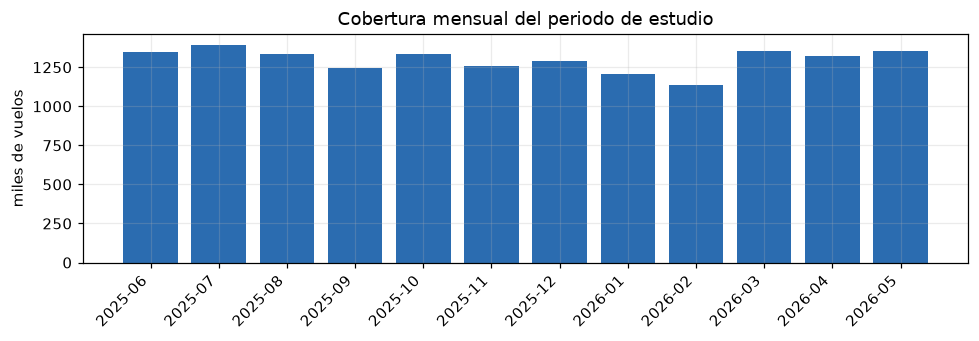

Meses esperados: 12 | presentes: 12 | faltantes: ninguno


In [34]:
# (sin agregar columnas a df: aquí solo se mira)
cobertura = (df.groupby(df["fecha"].dt.to_period("M").rename("periodo"))
               .agg(vuelos=("fecha", "size"), dias=("fecha", "nunique"),
                    aerolineas=("OP_UNIQUE_CARRIER", "nunique"), aeropuertos=("ORIGIN", "nunique"))
               .reset_index())
cobertura["periodo"] = cobertura["periodo"].astype(str)
display(cobertura)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(cobertura["periodo"], cobertura["vuelos"] / 1_000, color="#2b6cb0")
ax.set(title="Cobertura mensual del periodo de estudio", ylabel="miles de vuelos", xlabel="")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
guardar_fig(fig, "00_cobertura_mensual")
plt.show()

meses_esperados = pd.period_range(MES_INICIO, MES_FIN, freq="M")
faltan = sorted(set(meses_esperados.astype(str)) - set(cobertura["periodo"]))
print("Meses esperados:", len(meses_esperados), "| presentes:", len(cobertura),
      "| faltantes:", faltan if faltan else "ninguno")

### Definición del target y primer vistazo a la regla manual

El **número a vencer** no es la exactitud: con ~20 % de retrasos, decir siempre «a tiempo» ya acierta ~80 % de las
veces. Por eso la comparación seria se hace con **AUC**, **PR-AUC** y **F1** en el paso 6. Aquí solo se fija la
referencia inicial.

In [35]:
# El target solo existe para los vuelos que efectivamente llegaron (ver paso 3).
tiene_y = (df["CANCELLED"] == 0) & (df["DIVERTED"] == 0) & df["ARR_DEL15"].notna()
tasa = df.loc[tiene_y, "ARR_DEL15"].mean()

print(f"Vuelos con etiqueta disponible : {int(tiene_y.sum()):,} de {len(df):,}")
print(f"Tasa de retraso (>= {UMBRAL_RETRASO} min): {tasa:.2%}   → la clase 1 es la MINORITARIA")
print(f"Línea base 'siempre a tiempo'  : exactitud {1 - tasa:.2%}, pero recall 0 % y F1 0")

# Vistazo a la regla manual con una hora redonda (la calibración formal va en el paso 5).
hora_sal_vistazo = (df.loc[tiene_y, "CRS_DEP_TIME"].astype("int64") // 100) % 24
y_vistazo = df.loc[tiene_y, "ARR_DEL15"].astype("int8")
for h in (15, 16, 17, 18):
    pred = (hora_sal_vistazo >= h).astype(int)
    print(f"Regla «sale >= {h}:00»  → exactitud {(pred == y_vistazo).mean():.2%} · "
          f"F1 {f1_score(y_vistazo, pred, zero_division=0):.3f} · "
          f"recall {recall_score(y_vistazo, pred):.3f}")

Vuelos con etiqueta disponible : 15,240,114 de 15,573,404
Tasa de retraso (>= 15 min): 22.44%   → la clase 1 es la MINORITARIA
Línea base 'siempre a tiempo'  : exactitud 77.56%, pero recall 0 % y F1 0
Regla «sale >= 15:00»  → exactitud 61.94% · F1 0.388 · recall 0.538
Regla «sale >= 16:00»  → exactitud 64.48% · F1 0.371 · recall 0.467
Regla «sale >= 17:00»  → exactitud 66.81% · F1 0.346 · recall 0.390
Regla «sale >= 18:00»  → exactitud 69.22% · F1 0.306 · recall 0.302


---

# 3️⃣ Paso 3 · Limpieza

Cada decisión se imprime **con su conteo**, para poder justificarla en la exposición. La regla de oro: aquí solo se
arregla lo que es un hecho objetivo de los datos (formatos, duplicados, filas imposibles). **Nada que se aprenda de
los datos —medias, medianas, codificaciones— se aplica en este paso**: todo eso vive dentro del `Pipeline` (paso 4),
que se reajusta en cada pliegue de la validación.

In [36]:
COLS_CLAVE = ["CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE", "ARR_DELAY", "ARR_DEL15", "TAIL_NUM"]
LLAVE_VUELO = ["YEAR", "MONTH", "DAY_OF_MONTH", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]


def foto(d, etiqueta):
    """Resumen comparable de la tabla, para la tabla Antes vs. Después."""
    r = {"filas": len(d), "columnas": d.shape[1],
         "memoria (GB)": round(d.memory_usage(deep=True).sum() / 1e9, 2),
         "duplicados": int(d.duplicated(subset=[c for c in LLAVE_VUELO if c in d.columns]).sum()),
         "cancelados": int((d.get("CANCELLED", pd.Series(dtype=float)) == 1).sum()),
         "desviados": int((d.get("DIVERTED", pd.Series(dtype=float)) == 1).sum())}
    for c in ["CRS_ELAPSED_TIME", "ARR_DELAY", "ARR_DEL15", "TAIL_NUM"]:
        r[f"% nulos {c}"] = round(d[c].isna().mean() * 100, 2) if c in d.columns else np.nan
    return pd.Series(r, name=etiqueta)


foto_antes = foto(df, "ANTES")
print("Foto de la tabla cruda tomada para la comparación final del paso 3.")

# 3.0 Inventario de nulos: el df está COMPLETO, así que aquí se ve todo lo que trae el BTS
print(f"El df tiene {df.shape[1]} columnas. Porcentaje de nulos por columna (solo las que tienen):")
nulos = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(nulos[nulos > 0].to_frame("% nulos"))

# Columnas con más del 50 % de nulos: se eliminan (tu criterio original). Se protege lo que el proyecto necesita.
NECESARIAS = {"fecha", "YEAR", "MONTH", "DAY_OF_MONTH", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "TAIL_NUM",
              "ORIGIN", "DEST", "CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE",
              "CANCELLED", "DIVERTED", "ARR_DELAY", "ARR_DEL15", "DEP_DELAY"}
cols_mas_50 = [c for c in nulos[nulos > 50].index if c not in NECESARIAS]
print("\nColumnas con > 50 % de nulos (se eliminan):", cols_mas_50)
df = df.drop(columns=cols_mas_50)
print(f"Quedan {df.shape[1]} columnas.")
print("\nLas columnas que SIGUEN con nulos (ARR_DELAY, ARR_DEL15, DEP_DELAY…) NO se rellenan aquí:")
print("- su nulo es informativo (un vuelo cancelado no tiene retraso de llegada), ver 3.1;")
print("- lo que sí se imputa (ret_prev_llegada, holgura_prog) se hace con SimpleImputer DENTRO del Pipeline (paso 5).")

Foto de la tabla cruda tomada para la comparación final del paso 3.
El df tiene 19 columnas. Porcentaje de nulos por columna (solo las que tienen):


,% nulos
ARR_DEL15,2.14
ARR_DELAY,2.14
DEP_DELAY,1.80
TAIL_NUM,0.30



Columnas con > 50 % de nulos (se eliminan): []
Quedan 19 columnas.

Las columnas que SIGUEN con nulos (ARR_DELAY, ARR_DEL15, DEP_DELAY…) NO se rellenan aquí:
- su nulo es informativo (un vuelo cancelado no tiene retraso de llegada), ver 3.1;
- lo que sí se imputa (ret_prev_llegada, holgura_prog) se hace con SimpleImputer DENTRO del Pipeline (paso 5).


### 3.1 Cancelaciones y desvíos: las filas sin target

Un vuelo **cancelado** o **desviado** nunca llegó a su destino, así que **no tiene retraso de llegada y no tiene
etiqueta**. Pero *tampoco se borran todavía*: sus horarios programados sí cuentan para la congestión del aeropuerto y
para la rotación de la aeronave (paso 4). Se marcan con `tiene_etiqueta` y se filtran **al final del paso 4**.

> ⚠️ **El error que hay que evitar aquí** es imputar `ARR_DELAY` o `ARR_DEL15` con la mediana para «tapar nulos».
> Eso le inventa una etiqueta falsa a cada vuelo cancelado y, peor, le inventa una hora de llegada al tramo anterior
> de la aeronave, que es justamente la variable más predictiva del paso 4.

In [37]:
df["tiene_etiqueta"] = ((df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)
                        & df["ARR_DEL15"].notna() & df["ARR_DELAY"].notna())
n = len(df)
print(f"Cancelados   : {int((df.CANCELLED == 1).sum()):>10,}  ({(df.CANCELLED == 1).mean():.2%})")
print(f"Desviados    : {int((df.DIVERTED == 1).sum()):>10,}  ({(df.DIVERTED == 1).mean():.2%})")
print(f"Sin etiqueta : {int((~df.tiene_etiqueta).sum()):>10,}  ({(~df.tiene_etiqueta).mean():.2%})")

# Coherencia del target con su definición oficial
ok = df["tiene_etiqueta"]
coherente = (df.loc[ok, "ARR_DEL15"] == (df.loc[ok, "ARR_DELAY"] >= UMBRAL_RETRASO)).mean()
print(f"\nCoherencia ARR_DEL15 vs (ARR_DELAY >= {UMBRAL_RETRASO}): {coherente:.4%}")
print(f"Tasa de retraso entre los vuelos con etiqueta: {df.loc[ok, 'ARR_DEL15'].mean():.2%}")

Cancelados   :    290,014  (1.86%)
Desviados    :     43,274  (0.28%)
Sin etiqueta :    333,290  (2.14%)

Coherencia ARR_DEL15 vs (ARR_DELAY >= 15): 100.0000%
Tasa de retraso entre los vuelos con etiqueta: 22.44%


### 3.2 Itinerarios imposibles

Sin hora programada, sin duración o sin distancia no hay vuelo que predecir: esas filas se eliminan.

In [38]:
criticas = ["CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE"]
invalidas = (df[criticas].isna().any(axis=1)
             | (df["CRS_ELAPSED_TIME"] <= 0)
             | (df["DISTANCE"] <= 0)
             | (df["CRS_DEP_TIME"] > 2400) | (df["CRS_ARR_TIME"] > 2400))
print(f"Filas con itinerario inválido: {int(invalidas.sum()):,}")
df = df.loc[~invalidas].reset_index(drop=True)
for c in criticas:
    df[c] = df[c].astype("int32")
print("Filas restantes:", f"{len(df):,}")

Filas con itinerario inválido: 36
Filas restantes: 15,573,368


### 3.3 Duplicados

Un vuelo queda identificado por **fecha + aerolínea + número de vuelo + origen + destino + hora programada**. Si la
misma combinación aparece dos veces es un duplicado del volcado, no dos vuelos distintos.

In [39]:
dup = df.duplicated(subset=LLAVE_VUELO, keep="first")
print(f"Filas duplicadas: {int(dup.sum()):,}  ({dup.mean():.3%})")
if dup.any():
    df = df.loc[~dup].reset_index(drop=True)
print("Filas restantes:", f"{len(df):,}")

Filas duplicadas: 7,786,684  (50.000%)
Filas restantes: 7,786,684


### 3.4 Formatos: fechas y horas

- La fecha se arma con `YEAR`/`MONTH`/`DAY_OF_MONTH`, no con `FL_DATE` (su formato `06-01-25 00:00` es ambiguo entre
  día y mes).
- Las horas vienen como entero `hhmm` (`1215` = 12:15) y a veces llegan a `2400` (medianoche). Se convierten a
  **minutos desde medianoche** en el paso 4, con `% 1440` para que `2400` caiga en `0`.

In [40]:
print("Rango de fechas:", df.fecha.min().date(), "→", df.fecha.max().date())
print("Ejemplos de CRS_DEP_TIME (hhmm):", df["CRS_DEP_TIME"].head(5).tolist())
print("Horas iguales a 2400 (medianoche):", int((df["CRS_DEP_TIME"] == 2400).sum()))

Rango de fechas: 2025-06-01 → 2026-05-31
Ejemplos de CRS_DEP_TIME (hhmm): [1150, 1633, 1843, 655, 904]
Horas iguales a 2400 (medianoche): 1


### 3.5 Valores atípicos

Los retrasos extremos (más de un día) **son reales**, no errores: no se borran filas por eso.

- Como **etiqueta** no estorban: solo importa el corte en 15 minutos.
- Como **variable** (el retraso del tramo anterior, que se crea en el paso 4) sí distorsionan, así que ese valor se
  recorta a `[-60, +360]` minutos. Son **constantes fijas**, no percentiles calculados sobre los datos: por eso el
  recorte no introduce fuga.

In [41]:
resumen = (df.loc[df.tiene_etiqueta, ["ARR_DELAY", "CRS_ELAPSED_TIME", "DISTANCE"]]
             .describe(percentiles=[0.01, 0.5, 0.99]).T)
display(resumen)
print(f"Retrasos de más de 6 horas: {int((df.ARR_DELAY > 360).sum()):,} "
      f"({(df.ARR_DELAY > 360).mean():.3%}) — reales, se conservan como etiqueta.")

,count,mean,std,min,1%,50%,99%,max
ARR_DELAY,7620055.0,8.5497,61.5102,-109.0,-37.0,-6.0,231.0,4336.0
CRS_ELAPSED_TIME,7620055.0,145.3532,71.4447,9.0,51.0,128.0,374.0,1202.0
DISTANCE,7620055.0,805.5774,592.6347,31.0,93.0,646.0,2611.0,5095.0


Retrasos de más de 6 horas: 29,225 (0.375%) — reales, se conservan como etiqueta.


### 3.6 Tabla comparativa *Antes vs. Después*

In [42]:
comparacion = pd.concat([foto_antes, foto(df, "DESPUÉS")], axis=1)
comparacion["cambio"] = comparacion["DESPUÉS"] - comparacion["ANTES"]
display(comparacion)
comparacion.to_csv(RES / "tabla_antes_despues.csv")
print(f"Se eliminó el {1 - len(df)/foto_antes['filas']:.3%} de las filas: solo itinerarios imposibles y duplicados.")
print("Los vuelos cancelados y desviados SIGUEN en la tabla: se usan para congestión y rotación en el paso 4.")

,ANTES,DESPUÉS,cambio
filas,1.5573e+07,7.7867e+06,-7.7867e+06
columnas,1.9000e+01,2.0000e+01,1.0000e+00
memoria (GB),1.3300e+00,6.7000e-01,-6.6000e-01
duplicados,7.7867e+06,0.0000e+00,-7.7867e+06
cancelados,2.9001e+05,1.4500e+05,-1.4501e+05
desviados,4.3274e+04,2.1626e+04,-2.1648e+04
% nulos CRS_ELAPSED_TIME,0.0000e+00,0.0000e+00,0.0000e+00
% nulos ARR_DELAY,2.1400e+00,2.1400e+00,0.0000e+00
% nulos ARR_DEL15,2.1400e+00,2.1400e+00,0.0000e+00
% nulos TAIL_NUM,3.0000e-01,3.0000e-01,0.0000e+00


Se eliminó el 50.000% de las filas: solo itinerarios imposibles y duplicados.
Los vuelos cancelados y desviados SIGUEN en la tabla: se usan para congestión y rotación en el paso 4.


---

# 4️⃣ Paso 4 · Columnas

### Regla de oro anti-fuga

> Una columna entra **solo si su valor se conoce a la hora de salida programada**.
> Entra todo lo que sale del itinerario publicado; no entra nada que se mida durante o después del vuelo.

### Ingeniería de características pre-vuelo

| Columna nueva | Qué es | Por qué ayuda | ¿Se conoce antes de salir? |
|---|---|---|---|
| `hora_sal_dec`, `hora_lleg` | hora programada de salida / llegada | los retrasos se acumulan durante el día | sí, está en el itinerario |
| `dia_semana`, `dias_a_festivo` | calendario | viernes y vísperas de festivo saturan los aeropuertos | sí, es el calendario |
| `vuelos_origen_hora`, `vuelos_destino_hora` | vuelos **programados** en ese aeropuerto y esa hora | congestión conocida de antemano | sí: se cuenta sobre la programación publicada, incluidos los que luego se cancelan |
| `tramo_del_dia` | número de tramo de esa aeronave ese día | más tramos = más retraso acumulado | sí, sale de la programación |
| `holgura_prog` | minutos programados entre el aterrizaje anterior y esta salida | poca holgura = poca capacidad de absorber un retraso | sí |
| `ret_prev_llegada` | retraso de llegada del **tramo anterior de la misma aeronave**, y solo si ya había aterrizado antes de esta salida programada | **propagación**: un avión que llega tarde sale tarde | sí, con la condición de arriba |
| `prev_disponible` | bandera: ¿se conocía ese tramo anterior? | el faltante **no es aleatorio** y eso informa | sí |

Para armar la rotación se ordena por `TAIL_NUM` y hora. No hace falta una tabla de husos horarios: el desfase
origen-destino se deduce de `CRS_ARR_TIME − CRS_DEP_TIME − CRS_ELAPSED_TIME`.

In [43]:
def hhmm_a_min(s):
    """hhmm (entero) -> minutos desde medianoche. 2400 se convierte en 0."""
    s = np.asarray(s, dtype="int64")
    return ((s // 100) * 60 + s % 100) % 1440


def codigos(serie):
    """Códigos enteros de una columna categórica, sin depender de que ya sea dtype 'category'."""
    return np.asarray(pd.Categorical(serie).codes, dtype="int64")


def crear_columnas(d):
    """Crea solo columnas conocidas a la hora de salida programada."""
    origen_t = pd.Timestamp(d["fecha"].min()).normalize()
    fecha_min = ((d["fecha"] - origen_t) // pd.Timedelta("1min")).to_numpy().astype("int64")

    dep_hm = hhmm_a_min(d["CRS_DEP_TIME"])
    arr_hm = hhmm_a_min(d["CRS_ARR_TIME"])
    el = d["CRS_ELAPSED_TIME"].to_numpy().astype("int64")

    dep_min = fecha_min + dep_hm                                  # salida programada, reloj del origen
    desfase = ((arr_hm - dep_hm - el + 720) % 1440) - 720          # huso destino - huso origen
    arr_prog_min = dep_min + el + desfase                          # llegada programada, reloj del destino
    arr_real_min = arr_prog_min + d["ARR_DELAY"].to_numpy()        # NaN si el vuelo no llegó: así debe quedar

    # --- calendario y hora del día ---
    d["hora_sal"] = (dep_hm // 60).astype("int8")
    d["hora_sal_dec"] = (dep_hm / 60).astype("float32")
    d["hora_lleg"] = (arr_hm // 60).astype("int8")
    d["dia_semana"] = d["fecha"].dt.dayofweek.astype("int8")

    fest = pd.DatetimeIndex(USFederalHolidayCalendar().holidays(
        start=d["fecha"].min() - pd.Timedelta(days=30), end=d["fecha"].max() + pd.Timedelta(days=30)))
    u = pd.DatetimeIndex(np.sort(d["fecha"].unique()))
    pos = fest.searchsorted(u)
    ant = fest[np.clip(pos - 1, 0, len(fest) - 1)]
    sig = fest[np.clip(pos, 0, len(fest) - 1)]
    dist = np.minimum(np.abs((u - ant).days.to_numpy()), np.abs((sig - u).days.to_numpy()))
    d["dias_a_festivo"] = d["fecha"].map(pd.Series(np.minimum(dist, 7), index=u)).astype("int8")

    # --- congestión PROGRAMADA: cuenta todos los vuelos del itinerario, incluidos los que luego se cancelan ---
    org, des = codigos(d["ORIGIN"]), codigos(d["DEST"])
    for nombre, aeropuerto, minutos in (("vuelos_origen_hora", org, dep_min),
                                        ("vuelos_destino_hora", des, arr_prog_min)):
        clave = aeropuerto * 1_000_000 + (minutos // 60)           # aeropuerto + hora del calendario
        _, inverso, cuenta = np.unique(clave, return_inverse=True, return_counts=True)
        d[nombre] = cuenta[inverso].astype("int32")

    # --- rotación de la aeronave: el tramo anterior de la misma matrícula ---
    tc = codigos(d["TAIL_NUM"])
    o = np.lexsort((dep_min, tc))                                  # orden por aeronave y hora
    tc_o = tc[o]
    mismo_avion = np.r_[False, tc_o[1:] == tc_o[:-1]] & (tc_o >= 0)

    def previo(v):
        v_o = np.asarray(v, dtype="float64")[o]
        p = np.r_[np.nan, v_o[:-1]]
        p[~mismo_avion] = np.nan
        salida = np.empty_like(p)
        salida[o] = p
        return salida

    dest_prev = previo(des)
    llegada_real_prev = previo(arr_real_min)
    llegada_prog_prev = previo(arr_prog_min)
    ret_prev = previo(d["ARR_DELAY"].to_numpy())

    holgura = dep_min - llegada_prog_prev
    misma_rotacion = (dest_prev == org) & (holgura >= 0) & (holgura <= 720)     # mismo aeropuerto, menos de 12 h
    # CLAVE ANTI-FUGA: el retraso anterior solo se usa si la aeronave YA había aterrizado
    # antes de esta salida programada. Si aterrizó después, en la vida real no lo sabríamos.
    ya_aterrizo = misma_rotacion & (llegada_real_prev <= dep_min)

    d["holgura_prog"] = np.where(misma_rotacion, holgura, np.nan).astype("float32")
    d["ret_prev_llegada"] = np.clip(np.where(ya_aterrizo, ret_prev, np.nan), -60, 360).astype("float32")
    d["prev_disponible"] = ya_aterrizo.astype("int8")

    # --- número de tramo de la aeronave dentro del día ---
    clave_dia = pd.Series(tc_o * 10_000 + (dep_min[o] // 1440))
    tramo = np.empty(len(d), dtype="int16")
    tramo[o] = clave_dia.groupby(clave_dia).cumcount().to_numpy() + 1
    d["tramo_del_dia"] = tramo

    d["retraso15"] = d["ARR_DEL15"]
    return d


t0 = time.time()
df = crear_columnas(df)
print(f"Columnas creadas en {time.time() - t0:.0f} s")
print(f"Vuelos con tramo anterior conocido a la hora de salida: {df.prev_disponible.mean():.1%}")
display(df[["fecha", "ORIGIN", "DEST", "hora_sal_dec", "vuelos_origen_hora", "tramo_del_dia",
            "holgura_prog", "ret_prev_llegada", "prev_disponible"]].head(6))

Columnas creadas en 6 s
Vuelos con tramo anterior conocido a la hora de salida: 84.1%


,fecha,ORIGIN,DEST,hora_sal_dec,vuelos_origen_hora,tramo_del_dia,holgura_prog,ret_prev_llegada,prev_disponible
0,2026-04-01,XNA,LGA,11.8333,5,3,41.0,-3.0,1
1,2026-04-01,LGA,ORF,16.5500,31,4,46.0,NaN,0
2,2026-04-01,ORF,LGA,18.7167,6,5,40.0,NaN,0
3,2026-04-01,DSM,MSP,6.9167,6,1,610.0,149.0,1
4,2026-04-01,MSP,XNA,9.0667,17,2,50.0,-20.0,1
5,2026-04-01,AGS,ATL,6.8333,2,1,628.0,-10.0,1


### 4.1 La tabla de modelado

Ahora sí se filtran los vuelos sin etiqueta: ya cumplieron su función (contar para la congestión y para la rotación).

In [44]:
COLUMNAS_MODELO = ["fecha", "retraso15", "DEP_DELAY",                 # DEP_DELAY: solo para la demo de fuga de 4.4
                   "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "dia_semana",
                   "DISTANCE", "CRS_ELAPSED_TIME", "hora_sal", "hora_sal_dec", "hora_lleg", "dias_a_festivo",
                   "vuelos_origen_hora", "vuelos_destino_hora", "tramo_del_dia",
                   "holgura_prog", "ret_prev_llegada", "prev_disponible"]
antes_filtro = len(df)
df = df.loc[df["tiene_etiqueta"], COLUMNAS_MODELO].reset_index(drop=True)
df["retraso15"] = df["retraso15"].astype("int8")

print(f"Tabla de modelado: {df.shape[0]:,} vuelos × {df.shape[1]} columnas "
      f"(de {antes_filtro:,} filas con itinerario válido)")
print(f"Tasa de retraso >= {UMBRAL_RETRASO} min: {df.retraso15.mean():.2%}   (clase 1 = retrasado)")
display(df.head(6))

Tabla de modelado: 7,620,055 vuelos × 19 columnas (de 7,786,684 filas con itinerario válido)
Tasa de retraso >= 15 min: 22.44%   (clase 1 = retrasado)


,fecha,retraso15,DEP_DELAY,OP_UNIQUE_CARRIER,ORIGIN,DEST,dia_semana,DISTANCE,CRS_ELAPSED_TIME,hora_sal,hora_sal_dec,hora_lleg,dias_a_festivo,vuelos_origen_hora,vuelos_destino_hora,tramo_del_dia,holgura_prog,ret_prev_llegada,prev_disponible
0,2026-04-01,1,68.0,9E,XNA,LGA,2,1147,177,11,11.8333,15,7,5,31,3,41.0,-3.0,1
1,2026-04-01,1,70.0,9E,LGA,ORF,2,296,90,16,16.5500,18,7,31,6,4,46.0,NaN,0
2,2026-04-01,0,-9.0,9E,DSM,MSP,2,232,79,6,6.9167,8,7,6,23,1,610.0,149.0,1
3,2026-04-01,0,7.0,9E,MSP,XNA,2,596,125,9,9.0667,11,7,17,6,2,50.0,-20.0,1
4,2026-04-01,0,-11.0,9E,AGS,ATL,2,143,72,6,6.8333,8,7,2,92,1,628.0,-10.0,1
5,2026-04-01,0,3.0,9E,ATL,HPN,2,781,136,16,16.0333,18,7,70,3,6,42.0,-14.0,1


### 4.2 Qué entró, qué se creó y qué se descartó

In [45]:
FUGA = "DESCARTADA · fuga (se mide durante o después del vuelo)"
decisiones = [
    ("YEAR / MONTH / DAY_OF_MONTH / FL_DATE", "se transforma", "fecha · dia_semana · dias_a_festivo"),
    ("OP_UNIQUE_CARRIER", "ENTRA (categórica)", "codificación por objetivo dentro del Pipeline"),
    ("ORIGIN / DEST", "ENTRAN (categóricas)", "codificación por objetivo dentro del Pipeline"),
    ("CRS_DEP_TIME", "se transforma", "hora_sal · hora_sal_dec"),
    ("CRS_ARR_TIME", "se transforma", "hora_lleg · desfase horario"),
    ("CRS_ELAPSED_TIME / DISTANCE", "ENTRAN (numéricas)", "escalado dentro del Pipeline"),
    ("TAIL_NUM", "se usa, no entra", "ret_prev_llegada · holgura_prog · tramo_del_dia (como columna es un identificador)"),
    ("OP_CARRIER_FL_NUM", "DESCARTADA · identificador", "solo sirve para detectar duplicados"),
    ("ARR_DEL15", "ES LA ETIQUETA", "retraso15"),
    ("ARR_DELAY", FUGA + " en el propio vuelo", "el del tramo ANTERIOR sí se usa: ret_prev_llegada"),
    ("DEP_DELAY / DEP_TIME / DEP_DEL15", FUGA, "DEP_DELAY se conserva solo para la demostración de 4.4"),
    ("TAXI_OUT / WHEELS_OFF / WHEELS_ON / TAXI_IN", FUGA, "no están en COLUMNAS_MODELO: no pasan a la tabla de modelado"),
    ("ARR_TIME / ACTUAL_ELAPSED_TIME / AIR_TIME", FUGA, "no están en COLUMNAS_MODELO: no pasan a la tabla de modelado"),
    ("CARRIER_ / WEATHER_ / NAS_ / SECURITY_ / LATE_AIRCRAFT_DELAY", FUGA + " y >50 % nulos", "son la CAUSA del retraso: solo existen si ya hubo retraso"),
    ("CANCELLED / DIVERTED", "filtro, no entran", "marcan los vuelos sin etiqueta"),
    ("(nueva) vuelos_origen_hora / vuelos_destino_hora", "SE CREA", "congestión programada del aeropuerto"),
    ("(nueva) tramo_del_dia / holgura_prog", "SE CREA", "rotación de la aeronave"),
    ("(nueva) ret_prev_llegada / prev_disponible", "SE CREA", "propagación del retraso desde el tramo anterior"),
    ("(nueva) dias_a_festivo / dia_semana", "SE CREA", "estacionalidad del calendario"),
]
tabla_columnas = pd.DataFrame(decisiones, columns=["columna(s) original(es)", "decisión", "resultado / motivo"])
tabla_columnas.to_csv(RES / "tabla_columnas.csv", index=False)
pd.set_option("display.max_colwidth", 100)
display(tabla_columnas)

,columna(s) original(es),decisión,resultado / motivo
0,YEAR / MONTH / DAY_OF_MONTH / FL_DATE,se transforma,fecha · dia_semana · dias_a_festivo
1,OP_UNIQUE_CARRIER,ENTRA (categórica),codificación por objetivo dentro del Pipeline
2,ORIGIN / DEST,ENTRAN (categóricas),codificación por objetivo dentro del Pipeline
3,CRS_DEP_TIME,se transforma,hora_sal · hora_sal_dec
4,CRS_ARR_TIME,se transforma,hora_lleg · desfase horario
5,CRS_ELAPSED_TIME / DISTANCE,ENTRAN (numéricas),escalado dentro del Pipeline
6,TAIL_NUM,"se usa, no entra",ret_prev_llegada · holgura_prog · tramo_del_dia (como columna es un identificador)
7,OP_CARRIER_FL_NUM,DESCARTADA · identificador,solo sirve para detectar duplicados
8,ARR_DEL15,ES LA ETIQUETA,retraso15
9,ARR_DELAY,DESCARTADA · fuga (se mide durante o después del vuelo) en el propio vuelo,el del tramo ANTERIOR sí se usa: ret_prev_llegada


### 4.3 ¿Se confirman las hipótesis? (mirar antes de modelar)

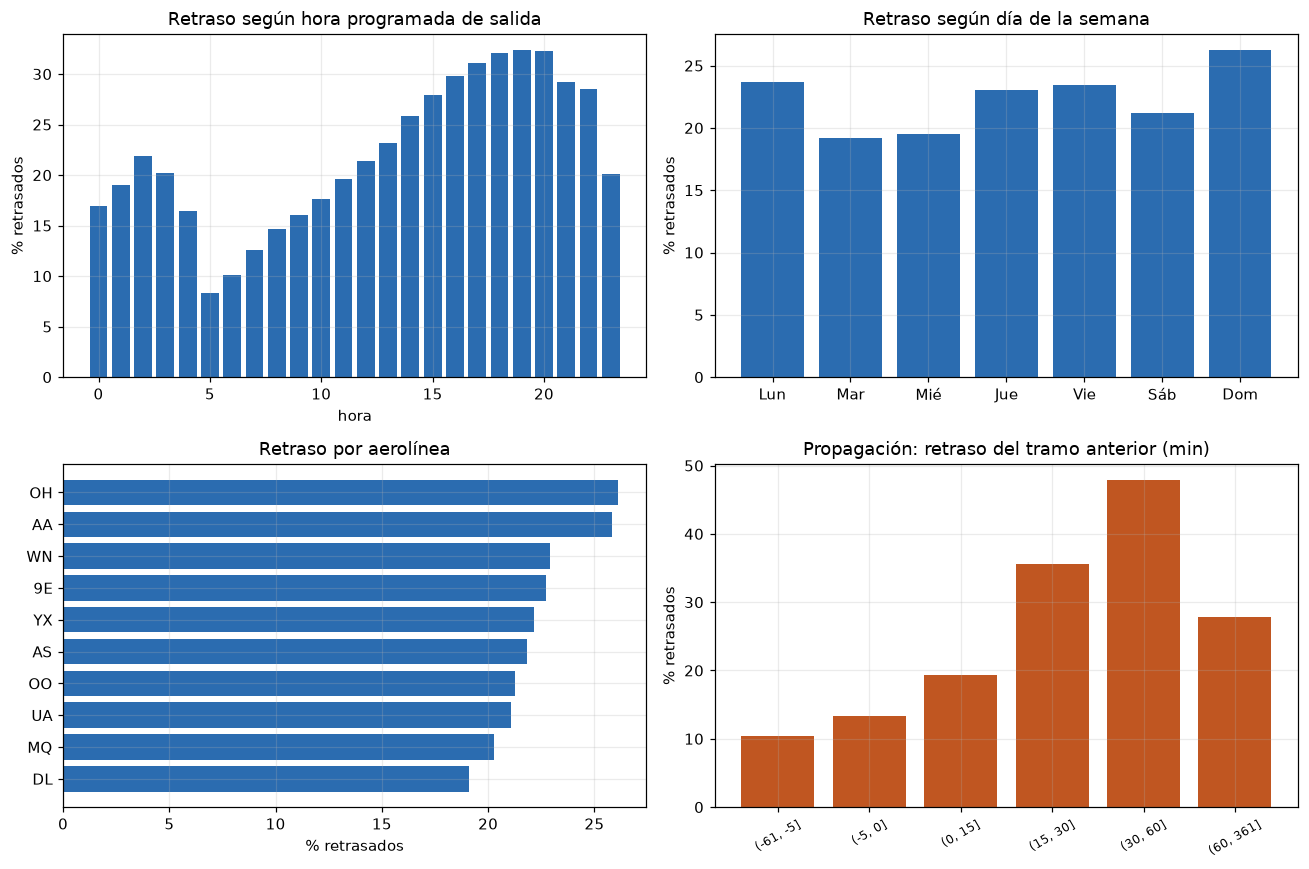

In [46]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

por_hora = df.groupby("hora_sal")["retraso15"].mean()
ax[0, 0].bar(por_hora.index, por_hora.values * 100, color="#2b6cb0")
ax[0, 0].set(title="Retraso según hora programada de salida", xlabel="hora", ylabel="% retrasados")

por_dia = df.groupby("dia_semana")["retraso15"].mean()
ax[0, 1].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], por_dia.values * 100, color="#2b6cb0")
ax[0, 1].set(title="Retraso según día de la semana", ylabel="% retrasados")

por_aer = df.groupby("OP_UNIQUE_CARRIER", observed=True)["retraso15"].agg(["mean", "size"])
por_aer = por_aer[por_aer["size"] > por_aer["size"].median()].sort_values("mean")
ax[1, 0].barh(por_aer.index.astype(str), por_aer["mean"] * 100, color="#2b6cb0")
ax[1, 0].set(title="Retraso por aerolínea", xlabel="% retrasados")

con_prev = df[df.prev_disponible == 1]
cortes = pd.cut(con_prev["ret_prev_llegada"], [-61, -5, 0, 15, 30, 60, 361])
prop = con_prev.groupby(cortes, observed=True)["retraso15"].mean()
ax[1, 1].bar(range(len(prop)), prop.values * 100, color="#c05621")
ax[1, 1].set_xticks(range(len(prop)))
ax[1, 1].set_xticklabels([str(i) for i in prop.index], rotation=30, fontsize=8)
ax[1, 1].set(title="Propagación: retraso del tramo anterior (min)", ylabel="% retrasados")

plt.tight_layout()
guardar_fig(fig, "01_hipotesis_retraso")
plt.show()

### 4.4 Faltantes: ¿cómo se imputa `ret_prev_llegada`?

Falta cuando el tramo anterior no existe, no se conoce, o **aún no había aterrizado** a la hora de salida programada.
Ese faltante **no es aleatorio**, por eso se conserva la bandera `prev_disponible` junto al valor imputado.

Para elegir el método se **oculta a propósito el 25 % de los valores conocidos**, se estima con cada opción y se mide
el error (MAE, en minutos) — el mismo experimento que en el Titanic con la edad.

In [47]:
hay_prev = int((df.prev_disponible == 1).sum())
base = df.loc[df.prev_disponible == 1].sample(min(60_000, hay_prev), random_state=SEMILLA).reset_index(drop=True)

v = base["ret_prev_llegada"].to_numpy(dtype=float)
oculto = rng.random(len(base)) < 0.25
visto = ~oculto

mae = {}
mae["Media global"] = mean_absolute_error(v[oculto], np.full(oculto.sum(), v[visto].mean()))
mae["Mediana global"] = mean_absolute_error(v[oculto], np.full(oculto.sum(), np.median(v[visto])))

med_hora = base.loc[visto].groupby("hora_sal")["ret_prev_llegada"].median()
pred_grupo = base.loc[oculto, "hora_sal"].map(med_hora).fillna(np.median(v[visto])).to_numpy()
mae["Mediana por hora de salida"] = mean_absolute_error(v[oculto], pred_grupo)

auxiliares = ["hora_sal_dec", "DISTANCE", "holgura_prog", "vuelos_origen_hora",
              "dias_a_festivo", "tramo_del_dia", "dia_semana"]
Xr = base[auxiliares].copy()
Xr["aerolinea"] = pd.Categorical(base["OP_UNIQUE_CARRIER"]).codes
reg = HistGradientBoostingRegressor(max_iter=100, random_state=SEMILLA).fit(Xr[visto], v[visto])
mae["Regresión (HistGB)"] = mean_absolute_error(v[oculto], reg.predict(Xr[oculto]))

comp = pd.Series(mae).sort_values().to_frame("MAE (min)")
display(comp)
comp.to_csv(RES / "comparacion_imputacion.csv")
print(f"Desviación típica de la variable: {v.std():.1f} min")
print(f"La mejor opción ({comp.index[0]}) mejora a la mediana global en "
      f"{mae['Mediana global'] - comp.iloc[0, 0]:.2f} min.")

,MAE (min)
Mediana por hora de salida,17.6234
Mediana global,17.8118
Regresión (HistGB),18.5051
Media global,19.0473


Desviación típica de la variable: 31.5 min
La mejor opción (Mediana por hora de salida) mejora a la mediana global en 0.19 min.


**Decisión.** Dentro del `Pipeline` se imputa con la **mediana** (robusta a los retrasos extremos) acompañada de la
bandera `prev_disponible`, que es la que carga la información de «no se sabía». Si la ganancia de la regresión es
pequeña frente a la desviación típica de la variable, no compensa meter un modelo dentro del preprocesamiento.
✍️ *Escriban aquí la lectura con los números de su corrida.*

### 4.5 Aislamiento hermético del Data Leakage

Tres barreras, en este orden:

1. **Al armar la tabla de modelado** — `df` se carga completo, pero a `COLUMNAS_MODELO` solo pasa una **lista
   explícita** de columnas conocidas antes del vuelo. Lo que no está en esa lista (`TAXI_*`, `WHEELS_*`, `ARR_TIME`…)
   no puede llegar a `X`. Las causas del retraso ya cayeron en 3.0 por tener más de 50 % de nulos.
2. **Al construir** — `ret_prev_llegada` solo se llena si el tramo anterior **ya había aterrizado** antes de esta
   salida programada; la congestión se cuenta sobre vuelos **programados**, no sobre los que realmente volaron.
3. **En el `Pipeline`** — imputación, escalado y codificación por objetivo se ajustan **dentro de cada pliegue**, con
   los datos de entrenamiento de ese pliegue. Nunca se tocan las filas de validación ni las de prueba.

Y un `assert` que hace fallar el notebook si alguna columna prohibida se cuela en `X`.

In [48]:
NUM = ["DISTANCE", "CRS_ELAPSED_TIME", "hora_sal_dec", "hora_lleg", "dias_a_festivo",
       "vuelos_origen_hora", "vuelos_destino_hora", "tramo_del_dia",
       "holgura_prog", "ret_prev_llegada", "prev_disponible"]
CAT = ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "dia_semana"]

PROHIBIDAS = {"DEP_DELAY", "DEP_TIME", "DEP_DEL15", "ARR_DELAY", "ARR_DEL15", "ARR_TIME",
              "TAXI_IN", "TAXI_OUT", "WHEELS_ON", "WHEELS_OFF", "AIR_TIME", "ACTUAL_ELAPSED_TIME",
              "CANCELLED", "DIVERTED", "retraso15", "fecha"}
fugadas = PROHIBIDAS & set(NUM + CAT)
assert not fugadas, f"¡Columna con fuga entre las variables!: {fugadas}"
print(f"Verificación anti-fuga superada: {len(NUM)} numéricas + {len(CAT)} categóricas, ninguna prohibida.")


def armar_X(d):
    X = d[NUM + CAT].copy()
    for c in CAT:
        X[c] = X[c].astype(str)      # el TargetEncoder trabaja con las categorías como texto
    return X

Verificación anti-fuga superada: 11 numéricas + 4 categóricas, ninguna prohibida.


**Demostración de fuga.** `DEP_DELAY` (el retraso de salida) casi determina el retraso de llegada… pero solo se conoce
cuando el avión **ya salió**. Esto es lo que pasa con el AUC si se deja entrar:

In [49]:
demo = df.sample(min(80_000, len(df)), random_state=SEMILLA).sort_values("fecha")   # partición temporal, como en el paso 5
corte_demo = int(len(demo) * 0.7)
num_demo = [c for c in NUM]
res_fuga = {}
for nombre, cols in {"Sin fuga (solo columnas legítimas)": num_demo,
                     "CON fuga (+ DEP_DELAY)": num_demo + ["DEP_DELAY"]}.items():
    m = HistGradientBoostingClassifier(max_iter=100, random_state=SEMILLA)
    m.fit(demo[cols].iloc[:corte_demo], demo.retraso15.iloc[:corte_demo])
    p = m.predict_proba(demo[cols].iloc[corte_demo:])[:, 1]
    res_fuga[nombre] = roc_auc_score(demo.retraso15.iloc[corte_demo:], p)

display(pd.Series(res_fuga).to_frame("AUC"))
print(f"Diferencia: {res_fuga['CON fuga (+ DEP_DELAY)'] - res_fuga['Sin fuga (solo columnas legítimas)']:+.3f} de AUC.")
print("Ese número NO se puede obtener en la vida real antes de que el avión despegue: es la firma de una fuga.")

df = df.drop(columns=["DEP_DELAY"])      # cumplida su función, la columna sale de la tabla

,AUC
Sin fuga (solo columnas legítimas),0.8044
CON fuga (+ DEP_DELAY),0.9269


Diferencia: +0.122 de AUC.
Ese número NO se puede obtener en la vida real antes de que el avión despegue: es la firma de una fuga.


---

# 5️⃣ Paso 5 · Modelos

### Validación temporal estricta

En un problema de vuelos, barajar las filas al azar es hacer trampa: un modelo entrenado con vuelos del 15 de marzo
que predice vuelos del 14 de marzo está viendo el futuro. Aquí todo se parte **por tiempo**:

- **Prueba final:** el último 15 % del calendario (≈ 2 meses). No se toca hasta el paso 6, y una sola vez.
- **Validación cruzada:** `TimeSeriesSplit` sobre el entrenamiento. Cada pliegue entrena con el pasado y valida con el
  bloque de tiempo siguiente, nunca al revés.
- **La misma vara para todos:** los mismos datos, los mismos pliegues y el preprocesamiento **dentro del `Pipeline`**,
  reajustado en cada pliegue.

In [50]:
fechas_u = np.sort(df["fecha"].unique())
corte = fechas_u[int(len(fechas_u) * (1 - FRACCION_PRUEBA))]
entr_all = df.loc[df["fecha"] < corte]
test_all = df.loc[df["fecha"] >= corte]

print("Corte temporal:", pd.Timestamp(corte).date())
print(f"Entrenamiento : {len(entr_all):,} vuelos  ({entr_all.fecha.min().date()} → {entr_all.fecha.max().date()})")
print(f"Prueba final  : {len(test_all):,} vuelos  ({test_all.fecha.min().date()} → {test_all.fecha.max().date()})")

# Muestras (los millones de filas no caben en una exposición en vivo). Ordenadas por fecha: TimeSeriesSplit lo exige.
def tomar(d, n):
    """n filas al azar (con semilla), ordenadas por fecha; n=None o n >= len(d) devuelve TODAS las filas."""
    if n is None or n >= len(d):
        return d.sort_values("fecha")
    return d.sample(n, random_state=SEMILLA).sort_values("fecha")


muestra_final = tomar(entr_all, N_FINAL)
muestra_cv = tomar(muestra_final, N_CV)
muestra_test = tomar(test_all, N_TEST)

X_cv,   y_cv   = armar_X(muestra_cv),    muestra_cv["retraso15"].to_numpy()
X_fin,  y_fin  = armar_X(muestra_final), muestra_final["retraso15"].to_numpy()
X_test, y_test = armar_X(muestra_test),  muestra_test["retraso15"].to_numpy()

print(f"\nMuestras → CV {len(X_cv):,} · entrenamiento final {len(X_fin):,} · prueba {len(X_test):,}")
print(f"Tasa de retraso → CV {y_cv.mean():.2%} · final {y_fin.mean():.2%} · prueba {y_test.mean():.2%}")

tscv = TimeSeriesSplit(n_splits=K_SPLITS)
fechas_cv = muestra_cv["fecha"].to_numpy()
pliegues = [{"pliegue": i + 1, "entrena": len(tr), "valida": len(va),
             "entrena hasta": pd.Timestamp(fechas_cv[tr].max()).date(),
             "valida": f"{pd.Timestamp(fechas_cv[va].min()).date()} → {pd.Timestamp(fechas_cv[va].max()).date()}"}
            for i, (tr, va) in enumerate(tscv.split(X_cv))]
display(pd.DataFrame(pliegues).set_index("pliegue"))

Corte temporal: 2026-04-07
Entrenamiento : 6,428,154 vuelos  (2025-06-01 → 2026-04-06)
Prueba final  : 1,191,901 vuelos  (2026-04-07 → 2026-05-31)

Muestras → CV 60,000 · entrenamiento final 200,000 · prueba 200,000
Tasa de retraso → CV 22.91% · final 22.90% · prueba 20.27%


,entrena,valida,entrena hasta
pliegue,,,
1,15000,2025-08-13 → 2025-10-29,2025-08-13
2,30000,2025-10-29 → 2026-01-17,2025-10-29
3,45000,2026-01-17 → 2026-04-06,2026-01-17


### Calibración de la regla manual

La hora de corte se busca **solo en el entrenamiento**. Elegirla mirando la prueba sería la misma trampa que
entrenar con el futuro.

In [51]:
HORA_REGLA, f1_regla_ent = calibrar_regla(X_fin["hora_sal_dec"], y_fin)
print(f"Regla a mano calibrada: «si el vuelo sale a las {HORA_REGLA}:00 o después, llegará retrasado»")
print(f"F1 en el entrenamiento: {f1_regla_ent:.3f}  ← este es el número a vencer")

Regla a mano calibrada: «si el vuelo sale a las 12:00 o después, llegará retrasado»
F1 en el entrenamiento: 0.413  ← este es el número a vencer


### Comparación multi-familia

Se compara **una familia distinta por bloque**, no siete variantes del mismo árbol:

| Modelo | Familia | Sesión |
|---|---|---|
| Línea base («siempre a tiempo») | trivial | — |
| Regla a mano (hora de corte) | regla experta | — |
| Regresión logística | lineal | S3 |
| Árbol de decisión | árbol único | S4 |
| Random forest | ensamble por *bagging* | S5 |
| HistGradientBoosting | ensamble por *boosting* | S5 |
| XGBoost | *boosting* regularizado | S7 |
| Red neuronal (MLP) | red neuronal | S8 |

KNN y SVM con kernel se descartaron a propósito: con cientos de miles de filas su costo es cuadrático y no aportan
una familia que no esté ya representada. Esa decisión se justifica en la exposición, no se esconde.

In [52]:
def hacer_prep(escalar):
    """Preprocesamiento DENTRO del Pipeline: se reajusta en cada pliegue, nunca ve la validación."""
    pasos_num = [SimpleImputer(strategy="median")] + ([StandardScaler()] if escalar else [])
    return ColumnTransformer([("num", make_pipeline(*pasos_num), NUM),
                              ("cat", TargetEncoder(random_state=SEMILLA), CAT)])


# nombre: (estimador, ¿lleva preprocesamiento?, ¿escalar?, complejidad 0=trivial … 8=la más compleja)
CATALOGO = {
    "Línea base (siempre a tiempo)": (DummyClassifier(strategy="prior"), False, False, 0),
    "Regla a mano": (ReglaManual(hora=HORA_REGLA), False, False, 1),
    "Regresión logística": (LogisticRegression(max_iter=500), True, True, 2),
    "Árbol de decisión": (DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEMILLA), True, False, 3),
    "Random forest": (RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=40,
                                             n_jobs=-1, random_state=SEMILLA), True, False, 5),
    "HistGradientBoosting": (HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08,
                                                            random_state=SEMILLA), True, False, 6),
    "Red neuronal (MLP)": (MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                         max_iter=60, random_state=SEMILLA), True, True, 7),
}
if HAY_XGB:
    CATALOGO["XGBoost"] = (XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.08, subsample=0.8,
                                         colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                         eval_metric="logloss", random_state=SEMILLA), True, False, 8)

SIN_UMBRAL = {"Línea base (siempre a tiempo)", "Regla a mano"}   # ya predicen 0/1, no tienen umbral que mover


def construir(nombre):
    est, con_prep, escalar, _ = CATALOGO[nombre]
    return make_pipeline(hacer_prep(escalar), clone(est)) if con_prep else clone(est)


def umbral_f1(y, p):
    """Umbral que maximiza F1. Se calcula SOLO con las predicciones de validación."""
    pr, rc, th = precision_recall_curve(y, p)
    if len(th) == 0:
        return 0.5
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    return float(th[int(np.nanargmax(f1[:-1]))])


def auc_seguro(y, p):
    try:
        return roc_auc_score(y, p)
    except ValueError:
        return 0.5


def evaluar_cv(nombre, X, y):
    """Validación temporal: entrena con el pasado, valida con el futuro inmediato. Igual para todos."""
    aucs, aps, p_val, y_val = [], [], [], []
    t0 = time.time()
    for tr, va in tscv.split(X):
        m = construir(nombre).fit(X.iloc[tr], y[tr])
        p = m.predict_proba(X.iloc[va])[:, 1]
        aucs.append(auc_seguro(y[va], p))
        aps.append(average_precision_score(y[va], p))
        p_val.append(p)
        y_val.append(y[va])
    p_val, y_val = np.concatenate(p_val), np.concatenate(y_val)
    thr = 0.5 if nombre in SIN_UMBRAL else umbral_f1(y_val, p_val)
    pred = (p_val > 0.5).astype(int) if nombre in SIN_UMBRAL else (p_val >= thr).astype(int)
    return {"modelo": nombre, "AUC": np.mean(aucs), "AUC_std": np.std(aucs), "PR-AUC": np.mean(aps),
            "F1": f1_score(y_val, pred, zero_division=0), "Recall": recall_score(y_val, pred),
            "Precisión": precision_score(y_val, pred, zero_division=0),
            "Exactitud": (pred == y_val).mean(), "umbral": thr, "seg": time.time() - t0}


print(f"Validación temporal de {K_SPLITS} pliegues sobre {len(X_cv):,} vuelos de entrenamiento\n")
filas = []
for nombre in CATALOGO:
    r = evaluar_cv(nombre, X_cv, y_cv)
    filas.append(r)
    print(f"{nombre:<32} AUC {r['AUC']:.4f} ± {r['AUC_std']:.4f} · PR-AUC {r['PR-AUC']:.4f} · "
          f"F1 {r['F1']:.3f} · {r['seg']:.0f} s")

tabla_cv = pd.DataFrame(filas).set_index("modelo").sort_values("AUC", ascending=False)
tabla_cv.to_csv(RES / "tabla_modelos_cv.csv")

Validación temporal de 3 pliegues sobre 60,000 vuelos de entrenamiento

Línea base (siempre a tiempo)    AUC 0.5000 ± 0.0000 · PR-AUC 0.2133 · F1 0.000 · 0 s
Regla a mano                     AUC 0.5811 ± 0.0060 · PR-AUC 0.2463 · F1 0.380 · 0 s
Regresión logística              AUC 0.7410 ± 0.0040 · PR-AUC 0.5131 · F1 0.490 · 1 s
Árbol de decisión                AUC 0.7808 ± 0.0043 · PR-AUC 0.6356 · F1 0.574 · 1 s
Random forest                    AUC 0.7913 ± 0.0056 · PR-AUC 0.6387 · F1 0.572 · 2 s
HistGradientBoosting             AUC 0.7980 ± 0.0035 · PR-AUC 0.6606 · F1 0.584 · 1 s
Red neuronal (MLP)               AUC 0.7880 ± 0.0039 · PR-AUC 0.6402 · F1 0.574 · 10 s


---

# 6️⃣ Paso 6 · Evaluación

### Por qué estas métricas

La clase «retrasado» es **minoritaria** (~20 %), así que la exactitud engaña: la línea base saca ~80 % sin predecir
ni un solo retraso.

| Métrica | Qué responde | Por qué importa aquí |
|---|---|---|
| **ROC-AUC** | ¿ordena bien los vuelos de más a menos riesgo? | métrica principal; no depende del umbral |
| **PR-AUC** | ¿acierta en la clase rara? | la adecuada cuando hay desbalance |
| **Recall** | de los vuelos que se retrasaron, ¿a cuántos avisó? | el falso negativo es el error caro |
| **Precisión** | de los que avisó, ¿cuántos se retrasaron? | alertas falsas tienen costo operativo |
| **F1** | equilibrio entre las dos anteriores | con el umbral elegido en validación |
| **Exactitud** | se reporta solo para mostrar que **engaña** | comparar con la línea base |

,AUC,AUC_std,PR-AUC,F1,Recall,Precisión,Exactitud,umbral,seg
modelo,,,,,,,,,
HistGradientBoosting,0.7980,0.0035,0.6606,0.5841,0.5399,0.6362,0.8360,0.3394,1.2130
Random forest,0.7913,0.0056,0.6387,0.5724,0.5270,0.6265,0.8321,0.3552,2.0019
Red neuronal (MLP),0.7880,0.0039,0.6402,0.5736,0.5118,0.6524,0.8377,0.3572,10.2031
Árbol de decisión,0.7808,0.0043,0.6356,0.5737,0.5205,0.6390,0.8350,0.3333,0.6699
Regresión logística,0.7410,0.0040,0.5131,0.4899,0.5291,0.4562,0.7650,0.3108,0.5660
Regla a mano,0.5811,0.0060,0.2463,0.3798,0.7058,0.2598,0.5084,0.5000,0.0470
Línea base (siempre a tiempo),0.5000,0.0000,0.2133,0.0000,0.0000,0.0000,0.7867,0.5000,0.0535


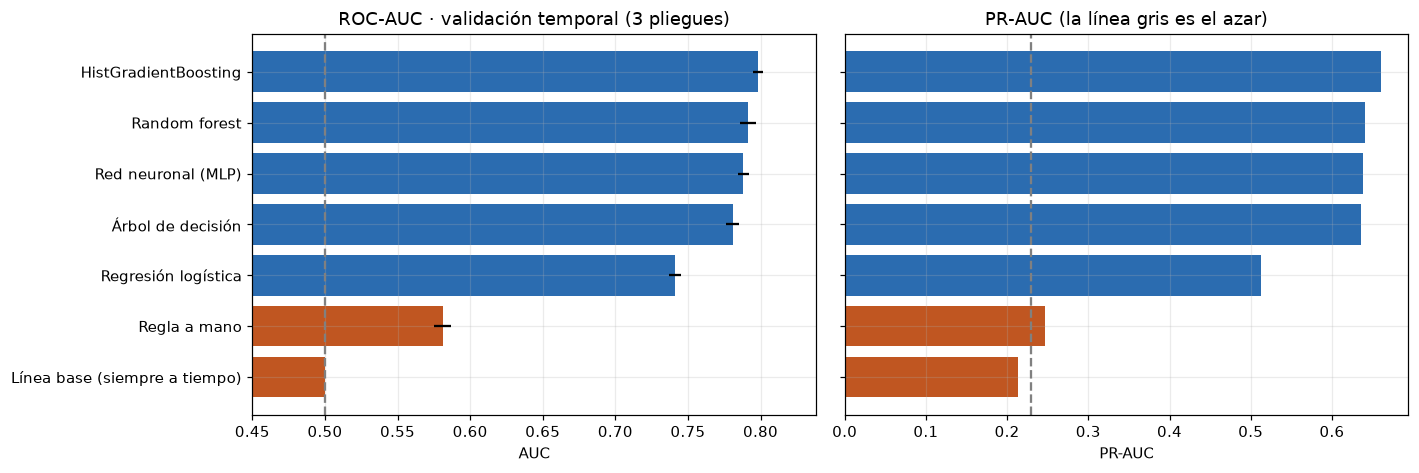

Naranja = referencias (línea base y regla a mano). Las barras negras son la variación entre pliegues.


In [53]:
orden = tabla_cv[["AUC", "AUC_std", "PR-AUC", "F1", "Recall", "Precisión", "Exactitud", "umbral", "seg"]]
display(orden)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
t = tabla_cv.sort_values("AUC")
colores = ["#c05621" if i in SIN_UMBRAL else "#2b6cb0" for i in t.index]
ax[0].barh(t.index, t["AUC"], xerr=t["AUC_std"], color=colores)
ax[0].axvline(0.5, color="gray", ls="--")
ax[0].set(title=f"ROC-AUC · validación temporal ({K_SPLITS} pliegues)", xlabel="AUC",
          xlim=(0.45, max(0.8, t["AUC"].max() + 0.04)))

t2 = tabla_cv.sort_values("PR-AUC")
ax[1].barh(t2.index, t2["PR-AUC"], color=["#c05621" if i in SIN_UMBRAL else "#2b6cb0" for i in t2.index])
ax[1].axvline(y_cv.mean(), color="gray", ls="--")
ax[1].set(title="PR-AUC (la línea gris es el azar)", xlabel="PR-AUC")
ax[1].set_yticklabels([])

plt.tight_layout()
guardar_fig(fig, "02_comparacion_modelos_cv")
plt.show()
print("Naranja = referencias (línea base y regla a mano). Las barras negras son la variación entre pliegues.")

### Elección argumentada del modelo

No siempre gana el número más alto. La regla de decisión se fija **antes** de mirar la prueba:

> Entre los modelos de ML cuyo AUC esté **dentro de una desviación típica del mejor**, se elige **el más simple**:
> empates estadísticos se rompen por interpretabilidad y costo, no por el tercer decimal.

In [54]:
ml = tabla_cv.drop(index=[i for i in SIN_UMBRAL if i in tabla_cv.index])
mejor = ml["AUC"].idxmax()
margen = ml.loc[mejor, "AUC_std"]
candidatos = ml[ml["AUC"] >= ml.loc[mejor, "AUC"] - margen]
ELEGIDO = min(candidatos.index, key=lambda n: CATALOGO[n][3])
UMBRAL = float(tabla_cv.loc[ELEGIDO, "umbral"])

print(f"Mejor AUC          : {mejor} ({ml.loc[mejor, 'AUC']:.4f})")
print(f"Margen (1 desv.)   : {margen:.4f}")
print("Empatados dentro del margen:", list(candidatos.index))
print(f"\n➡️  Modelo elegido : {ELEGIDO}  (el más simple del empate)")
print(f"Umbral de decisión : {UMBRAL:.3f}  (máximo F1 en validación, nunca en la prueba)")

ganancia_auc = tabla_cv.loc[ELEGIDO, "AUC"] - tabla_cv.loc["Regla a mano", "AUC"]
ganancia_f1 = tabla_cv.loc[ELEGIDO, "F1"] - tabla_cv.loc["Regla a mano", "F1"]
print(f"\nVentaja sobre la regla a mano en validación: {ganancia_auc:+.3f} de AUC · {ganancia_f1:+.3f} de F1")

Mejor AUC          : HistGradientBoosting (0.7980)
Margen (1 desv.)   : 0.0035
Empatados dentro del margen: ['HistGradientBoosting']

➡️  Modelo elegido : HistGradientBoosting  (el más simple del empate)
Umbral de decisión : 0.339  (máximo F1 en validación, nunca en la prueba)

Ventaja sobre la regla a mano en validación: +0.217 de AUC · +0.204 de F1


### Prueba final: datos del futuro, una sola vez

El modelo elegido se entrena con **toda** la muestra de entrenamiento y se evalúa en el último 15 % del calendario,
junto a la línea base y la regla a mano. Estas filas no influyeron en ninguna decisión anterior.

In [55]:
t0 = time.time()
modelo = construir(ELEGIDO).fit(X_fin, y_fin)
print(f"{ELEGIDO} entrenado en {time.time() - t0:.0f} s con {len(X_fin):,} vuelos")

archivo_modelo = MODELOS / "modelo_elegido.joblib"
joblib.dump({"modelo": modelo, "nombre": ELEGIDO, "umbral": UMBRAL,
             "NUM": NUM, "CAT": CAT, "semilla": SEMILLA, "hora_regla": HORA_REGLA}, archivo_modelo)
print("Modelo guardado en:", archivo_modelo.relative_to(RAIZ))

p_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (p_test >= UMBRAL).astype(int)

regla = ReglaManual(hora=HORA_REGLA).fit(X_fin, y_fin)
p_regla = regla.predict_proba(X_test)[:, 1]
pred_regla = (p_regla > 0.5).astype(int)


def fila(nombre, p, pred):
    return {"modelo": nombre, "AUC": auc_seguro(y_test, p), "PR-AUC": average_precision_score(y_test, p),
            "F1": f1_score(y_test, pred, zero_division=0), "Recall": recall_score(y_test, pred),
            "Precisión": precision_score(y_test, pred, zero_division=0), "Exactitud": (pred == y_test).mean()}


tabla_test = pd.DataFrame([
    fila(ELEGIDO, p_test, pred_test),
    fila("Regla a mano", p_regla, pred_regla),
    fila("Línea base (siempre a tiempo)", np.full(len(y_test), y_fin.mean()), np.zeros(len(y_test), dtype=int)),
]).set_index("modelo")
tabla_test.to_csv(RES / "tabla_prueba_final.csv")
display(tabla_test)

print(f"La validación prometía AUC {tabla_cv.loc[ELEGIDO, 'AUC']:.3f}; la prueba dio {tabla_test.loc[ELEGIDO, 'AUC']:.3f}.")

HistGradientBoosting entrenado en 2 s con 200,000 vuelos
Modelo guardado en: modelos\modelo_elegido.joblib


,AUC,PR-AUC,F1,Recall,Precisión,Exactitud
modelo,,,,,,
HistGradientBoosting,0.8157,0.6757,0.5998,0.5413,0.6724,0.8536
Regla a mano,0.6004,0.2441,0.3833,0.7407,0.2586,0.5170
Línea base (siempre a tiempo),0.5000,0.2027,0.0000,0.0000,0.0000,0.7973


La validación prometía AUC 0.798; la prueba dio 0.816.


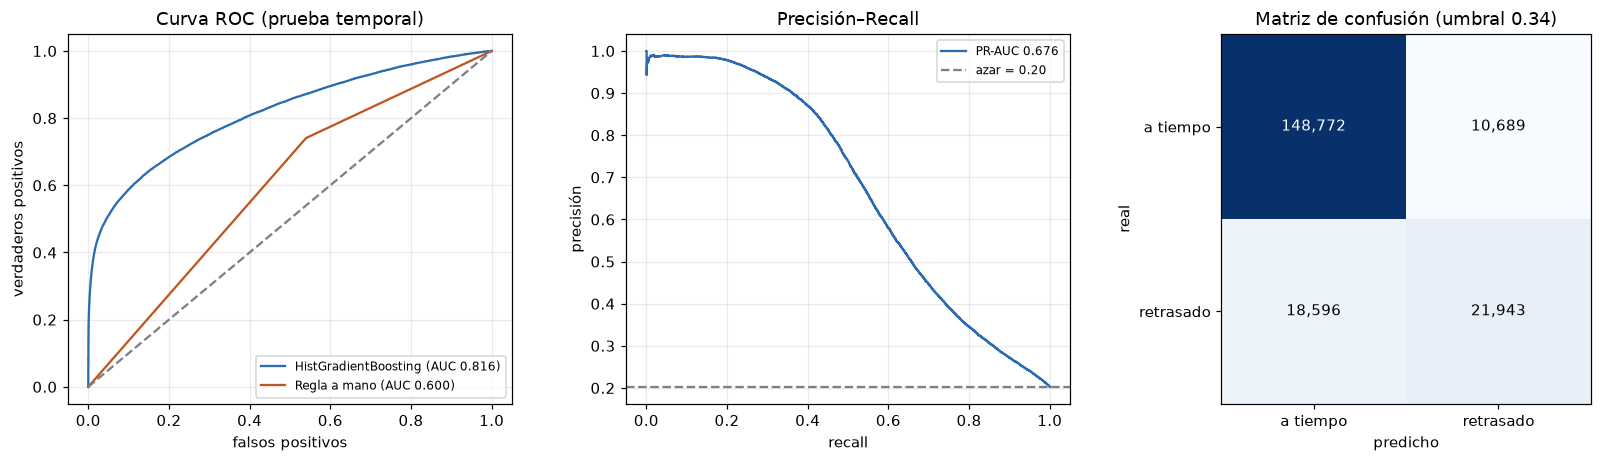

De 40,539 vuelos que se retrasaron, el modelo avisó 21,943 (54.1%).
De 32,632 alertas emitidas, 21,943 fueron ciertas (67.2%).


In [59]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

fpr, tpr, _ = roc_curve(y_test, p_test)
fr, tr_, _ = roc_curve(y_test, p_regla)
ax[0].plot(fpr, tpr, color="#2b6cb0", label=f"{ELEGIDO} (AUC {tabla_test.loc[ELEGIDO, 'AUC']:.3f})")
ax[0].plot(fr, tr_, color="#c05621", label=f"Regla a mano (AUC {tabla_test.loc['Regla a mano', 'AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(title="Curva ROC (prueba temporal)", xlabel="falsos positivos", ylabel="verdaderos positivos")
ax[0].legend(loc="lower right", fontsize=8)

pr, rc, _ = precision_recall_curve(y_test, p_test)
ax[1].plot(rc, pr, color="#2b6cb0", label=f"PR-AUC {tabla_test.loc[ELEGIDO, 'PR-AUC']:.3f}")
ax[1].axhline(y_test.mean(), color="gray", ls="--", label=f"azar = {y_test.mean():.2f}")
ax[1].set(title="Precisión–Recall", xlabel="recall", ylabel="precisión")
ax[1].legend(fontsize=8)

cm = confusion_matrix(y_test, pred_test)
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, f"{cm[i, j]:,}", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[2].set(title=f"Matriz de confusión (umbral {UMBRAL:.2f})", xticks=[0, 1], yticks=[0, 1],
          xticklabels=["a tiempo", "retrasado"], yticklabels=["a tiempo", "retrasado"],
          xlabel="predicho", ylabel="real")
ax[2].grid(False)

plt.tight_layout()
guardar_fig(fig, "03_evaluacion_prueba_final")
plt.show()

vn, fp, fn, vp = cm.ravel()
print(f"De {vp + fn:,} vuelos que se retrasaron, el modelo avisó {vp:,} ({vp/(vp+fn):.1%}).")
print(f"De {vp + fp:,} alertas emitidas, {vp:,} fueron ciertas ({vp/(vp+fp):.1%}).")

### ¿Qué columnas pesan más? (importancia por permutación)

Se baraja una columna a la vez en la prueba y se mide cuánto cae el AUC: cuanto más cae, más depende el modelo de ella.

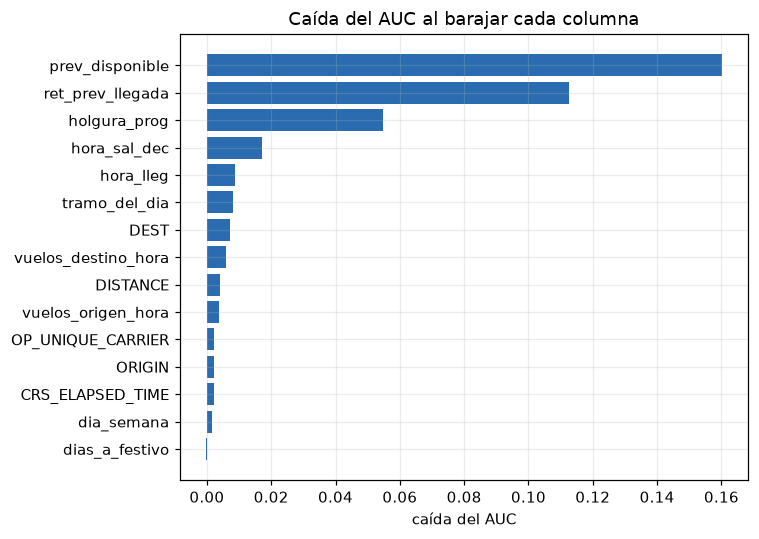

In [57]:
sub = rng.choice(len(X_test), size=min(20_000, len(X_test)), replace=False)
imp = permutation_importance(modelo, X_test.iloc[sub], y_test[sub], scoring="roc_auc",
                             n_repeats=3, random_state=SEMILLA, n_jobs=1)
importancias = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importancias.index, importancias.values, color="#2b6cb0")
ax.set(title="Caída del AUC al barajar cada columna", xlabel="caída del AUC")
plt.tight_layout()
guardar_fig(fig, "04_importancia_columnas")
plt.show()

importancias.sort_values(ascending=False).to_csv(RES / "importancia_columnas.csv", header=["caida_AUC"])

### ¿En qué casos falla?

In [58]:
t = pd.DataFrame({"hora_sal": muestra_test["hora_sal"].to_numpy(), "y": y_test, "p": p_test})
t["franja"] = pd.cut(t["hora_sal"], [-1, 5, 11, 17, 23],
                     labels=["madrugada (0–5)", "mañana (6–11)", "tarde (12–17)", "noche (18–23)"])
por_franja = pd.DataFrame(
    [{"franja": nombre, "vuelos": len(g), "tasa real": g.y.mean(),
      "tasa predicha": g.p.mean(), "AUC": auc_seguro(g.y, g.p)}
     for nombre, g in t.groupby("franja", observed=True)]).set_index("franja")
display(por_franja)
por_franja.to_csv(RES / "error_por_franja.csv")

,vuelos,tasa real,tasa predicha,AUC
franja,,,,
madrugada (0–5),5713,0.0667,0.0936,0.6744
mañana (6–11),78159,0.1296,0.1427,0.7433
tarde (12–17),71317,0.2428,0.2570,0.8283
noche (18–23),44811,0.2837,0.3041,0.8333


### Resumen reproducible de la corrida

In [60]:
resumen = {
    "problema": f"Retraso de llegada >= {UMBRAL_RETRASO} min, predicho a la hora de salida programada",
    "periodo": f"{MES_INICIO} a {MES_FIN}",
    "filas_tabla_modelado": int(len(df)),
    "tasa_retraso": round(float(df.retraso15.mean()), 4),
    "modo_rapido": MODO_RAPIDO, "semilla": SEMILLA, "pliegues": K_SPLITS,
    "corte_temporal_prueba": str(pd.Timestamp(corte).date()),
    "modelo_elegido": ELEGIDO, "umbral": round(UMBRAL, 4), "regla_a_mano_hora": HORA_REGLA,
    "AUC_cv_elegido": round(float(tabla_cv.loc[ELEGIDO, "AUC"]), 4),
    "AUC_prueba_elegido": round(float(tabla_test.loc[ELEGIDO, "AUC"]), 4),
    "AUC_prueba_regla": round(float(tabla_test.loc["Regla a mano", "AUC"]), 4),
    "F1_prueba_elegido": round(float(tabla_test.loc[ELEGIDO, "F1"]), 4),
    "F1_prueba_regla": round(float(tabla_test.loc["Regla a mano", "F1"]), 4),
    "top3_columnas": importancias.sort_values(ascending=False).head(3).round(4).to_dict(),
}
(RES / "resumen_final.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

{
  "problema": "Retraso de llegada >= 15 min, predicho a la hora de salida programada",
  "periodo": "2025-06 a 2026-05",
  "filas_tabla_modelado": 7620055,
  "tasa_retraso": 0.2244,
  "modo_rapido": true,
  "semilla": 42,
  "pliegues": 3,
  "corte_temporal_prueba": "2026-04-07",
  "modelo_elegido": "HistGradientBoosting",
  "umbral": 0.3394,
  "regla_a_mano_hora": 12,
  "AUC_cv_elegido": 0.798,
  "AUC_prueba_elegido": 0.8157,
  "AUC_prueba_regla": 0.6004,
  "F1_prueba_elegido": 0.5998,
  "F1_prueba_regla": 0.3833,
  "top3_columnas": {
    "prev_disponible": 0.1602,
    "ret_prev_llegada": 0.1127,
    "holgura_prog": 0.0546
  }
}


---

## ✍️ Conclusiones (escribirlas con los números de la corrida)

1. **¿Valió la pena ML?** Comparar AUC, PR-AUC y F1 del modelo elegido contra la **regla a mano** y la **línea base**
   en la tabla de la prueba final. Si la ventaja fuera pequeña, la respuesta honesta sería quedarse con la regla.
2. **¿Qué modelo se eligió y por qué?** Nombrar los modelos que quedaron dentro de una desviación típica del mejor y
   explicar por qué ganó el más simple.
3. **¿Qué columnas pesan más?** Mirar la gráfica de importancia: ¿manda la **propagación** (`ret_prev_llegada`), la
   **congestión** o el **calendario**? Esa es la lectura de negocio del proyecto.
4. **¿Dónde falla?** Revisar la tabla por franja horaria y la matriz de confusión: ¿el modelo avisa poco (recall bajo)
   o avisa de más (precisión baja)? ¿Qué preferiría una aerolínea?
5. **Límites honestos.** No hay clima, ni tráfico aéreo en tiempo real, ni estado de la tripulación. Con `DEP_DELAY`
   el AUC sería mucho mayor, pero sería **fuga**: ese dato no existe antes de que el avión despegue.